# 03 · From flickering frames to words and subtitles

The model guesses a letter on every frame. `LetterStream` turns that into committed letters: smooth the
probabilities, commit a letter once it is confidently on top for 0.2 s, require a "release" before repeating
a letter (double letters), and end a word when the hand disappears. Journal 06 explains the rules.

Here a word is spelled with **real frames from session 4**, with blended in-between frames to imitate the hand
moving between letters.

In [1]:
%matplotlib inline
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)                       # paths below are relative to the repo root
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110

In [2]:
from aslcv.model import LetterModel
from aslcv.infer import LetterStream, transcript
from aslcv.simulate import frames_for
from aslcv.subtitles import events_to_cues, format_srt

model = LetterModel.load("models/letter_mlp_final.npz")
s4 = np.load("data/recorded/20261011-020828.npz")
frames = frames_for("HELLO BOOK", s4["X"], s4["y"], np.random.default_rng(1))

stream = LetterStream.for_fps(model.classes, fps=30)
events, top, conf = [], [], []
for i, (f, motion) in enumerate(frames):
    p = None if f is None else model.predict_proba(f)
    events += stream.update(p, t=i / 30, motion=motion)
    letter, c = stream.current
    top.append(letter); conf.append(c)
print("transcript:", transcript(events))

transcript: ZELLO BOOK


**H came out as Z.** H is one of the letters I signed differently in session 4 than in my training sessions
(turned further sideways; see journal 09), so the model reads a different letter. The smoothing itself did its job:
the double L and double O are both there.

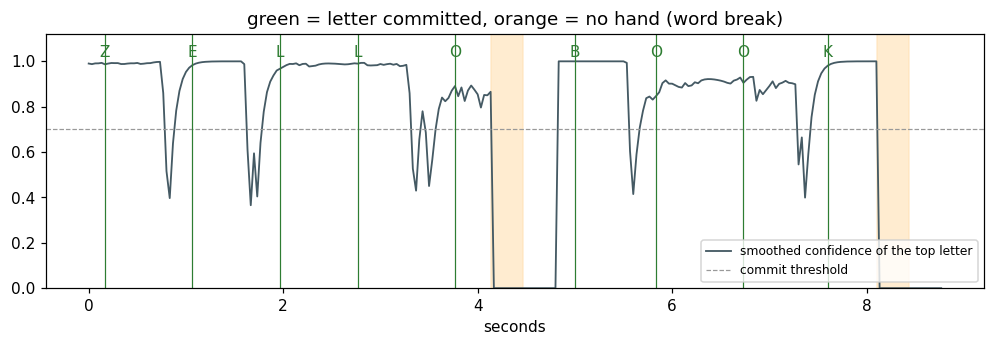

In [3]:
t = np.arange(len(frames)) / 30
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(t, conf, color="#455a64", lw=1.2, label="smoothed confidence of the top letter")
ax.axhline(0.7, color="#999", ls="--", lw=0.8, label="commit threshold")
for e in events:
    if e.kind == "letter":
        ax.axvline(e.t_commit, color="#2e7d32", lw=0.8)
        ax.text(e.t_commit, 1.02, e.value, ha="center", fontsize=10, color="#2e7d32")
    else:
        ax.axvspan(e.t_commit - 0.33, e.t_commit, color="#ffe0b2", alpha=0.6)
ax.set_ylim(0, 1.12); ax.set_xlabel("seconds"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("green = letter committed, orange = no hand (word break)")
plt.show()

## The same events as subtitles

In [4]:
print(format_srt(events_to_cues(events)))

1
00:00:00,000 --> 00:00:04,467
ZELLO

2
00:00:04,833 --> 00:00:08,433
BOOK




## And on a real video of a stranger

The video translator runs this exact chain on real footage. The first real-world test (journal 11) is recorded in
`artifacts/realworld_travis_run2.json`: the alphabet signed by someone the model has never seen.

In [5]:
import json
rec = json.loads(Path("artifacts/realworld_travis_run2.json").read_text())
print("correct:", rec["truth"]); print("output: ", rec["output_scored"])
print("letters right:", rec["counts"]["ok"], "/ 26 | error rate:", rec["char_error_rate"])
print(" ".join(a["truth"] if a["result"] == "ok" else f"{a['truth'] or '-'}>{a['output'] or '-'}" for a in rec["alignment"]))

correct: ABCDEFGHIJKLMNOPQRSTUVWXYZ
output:  OIRTHZIARLONONNRSZTUVWZYZACLC
letters right: 12 / 26 | error rate: 0.731
A>- B>- C>O D>I E>R F>T G>H H>Z I J>A K>R L M>O N O P>N Q>N R S ->Z T U V W X>Z Y Z ->A ->C ->L ->C
